In [2]:
import torch
from torch import nn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

# 1. Prepare data

## 1.1 Download dataset

使用的数据集: PyTorch 内置数据集 Food-101(101种food)的精简版 —— 10%图片, 3种food

Why?
- 当你开始ML问题时, 从小数据集开始, 如果有效, 再扩展到大数据集

In [4]:
import requests
import zipfile
from pathlib import Path

DATA_DIR = Path("data")
IMAGE_PATH = DATA_DIR / "pizza_steak_sushi"

if DATA_DIR.is_dir():
    print(f"data dir {DATA_DIR} already exists.")
else:
    print(f"data dir {DATA_DIR} does not exist, creating one.")
    DATA_DIR.mkdir(parents=True, exist_ok=True)

with open(DATA_DIR / "pizza_steak_sushi.zip", 'wb') as f:
    request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/refs/heads/main/data/pizza_steak_sushi.zip")
    print("Downloading data...")
    f.write(request.content)

with zipfile.ZipFile(DATA_DIR / "pizza_steak_sushi.zip", 'r') as zip_ref:
    print("Unzipping...")
    zip_ref.extractall(IMAGE_PATH)

data dir data already exists.
Unzipping...


## 1.2 Explore Data

In [5]:
import os

def walk_through_dir(path: Path) -> None:
    for dirpath, dirnames, filenames, in os.walk(path):
        print(f"目录 {dirpath} 有 {len(dirnames)} 个子目录, {len(filenames)} 个图片")

walk_through_dir(IMAGE_PATH)

目录 data\pizza_steak_sushi 有 2 个子目录, 0 个图片
目录 data\pizza_steak_sushi\test 有 3 个子目录, 0 个图片
目录 data\pizza_steak_sushi\test\pizza 有 0 个子目录, 25 个图片
目录 data\pizza_steak_sushi\test\steak 有 0 个子目录, 19 个图片
目录 data\pizza_steak_sushi\test\sushi 有 0 个子目录, 31 个图片
目录 data\pizza_steak_sushi\train 有 3 个子目录, 0 个图片
目录 data\pizza_steak_sushi\train\pizza 有 0 个子目录, 78 个图片
目录 data\pizza_steak_sushi\train\steak 有 0 个子目录, 75 个图片
目录 data\pizza_steak_sushi\train\sushi 有 0 个子目录, 72 个图片


In [6]:
TRAIN_PATH = IMAGE_PATH / "train"
TEST_PATH = IMAGE_PATH / "test"
TRAIN_PATH, TEST_PATH

(WindowsPath('data/pizza_steak_sushi/train'),
 WindowsPath('data/pizza_steak_sushi/test'))

In [7]:
IMAGE_PATH

WindowsPath('data/pizza_steak_sushi')

In [8]:
image_path_list = list(IMAGE_PATH.glob("*/*/*.jpg"))
image_path_list[:5]

[WindowsPath('data/pizza_steak_sushi/test/pizza/1152100.jpg'),
 WindowsPath('data/pizza_steak_sushi/test/pizza/1503858.jpg'),
 WindowsPath('data/pizza_steak_sushi/test/pizza/1687143.jpg'),
 WindowsPath('data/pizza_steak_sushi/test/pizza/1925494.jpg'),
 WindowsPath('data/pizza_steak_sushi/test/pizza/194643.jpg')]

image_path: data\pizza_steak_sushi\test\sushi\2394442.jpg
image_class: sushi
testing data
width: 512 x height: 408


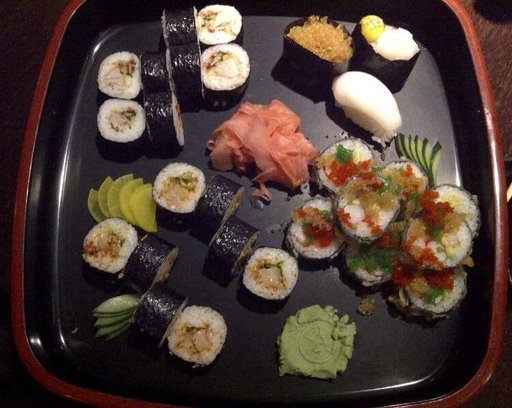

In [9]:
# VISUALIZE
import random
from PIL import Image

RANDOM_SEED = 42
random.seed(RANDOM_SEED)

image_path_sample = random.choice(image_path_list)
image_class = image_path_sample.parent.stem # pizza/steak/sushi
image_data_type = image_path_sample.parent.parent.stem # train/test

img = Image.open(image_path_sample) # open image

print(f"image_path: {image_path_sample}")
print(f"image_class: {image_class}")
print(f"{image_data_type}ing data")
print(f"width: {img.width} x height: {img.height}")

img

(np.float64(-0.5), np.float64(511.5), np.float64(407.5), np.float64(-0.5))

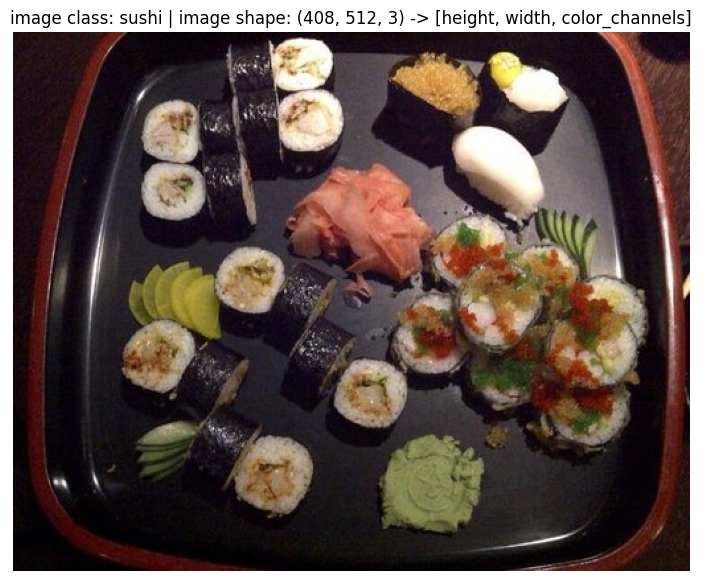

In [10]:
# use matplotlib to visualize
image_as_arr = np.asarray(img)
plt.figure(figsize=(10, 7))
plt.imshow(image_as_arr)
plt.title(f"image class: {image_class} | image shape: {image_as_arr.shape} -> [height, width, color_channels]")
plt.axis(False)

# 2. Transforming data

使用data with Pytorch:
1. turn into `tensor`
2. turn into `dataset`
3. turn into `dataloader`

In [11]:
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

# 也可以用nn.Sequential
data_transfrom = transforms.Compose([
    # resize
    transforms.Resize(size=(64, 64)),
    # flip horizontally randomly
    transforms.RandomHorizontalFlip(p=0.5),
    # turn into a tensor
    transforms.ToTensor()
])

In [12]:
transformed_img = data_transfrom(img)
image_as_arr.shape, transformed_img.shape

((408, 512, 3), torch.Size([3, 64, 64]))

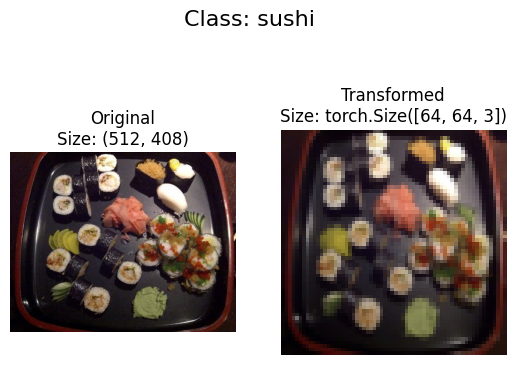

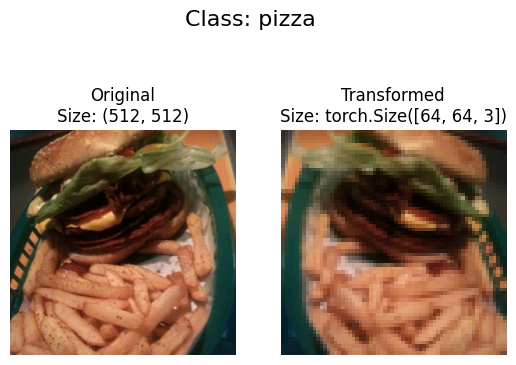

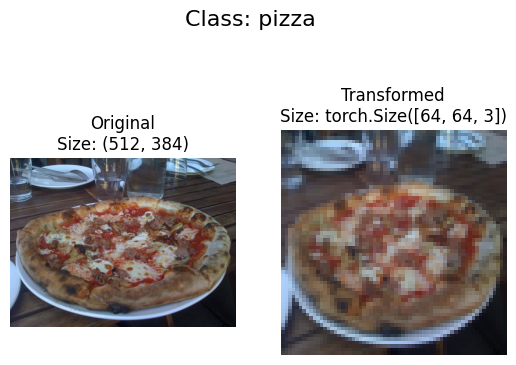

In [13]:
# plot transformed img and compare with the original ones
def plot_random_transformed_img(image_path_list: list, transform: transforms.Compose, n: int=3, seed: int | None=None) -> None:
    if seed is not None:
        random.seed(seed)
    random_image_paths = random.sample(image_path_list, k=n)
    for image_path in random_image_paths:
        with Image.open(image_path) as f:
            fig, ax = plt.subplots(nrows=1, ncols=2)
            # plot original
            ax[0].imshow(f)
            ax[0].set_title(f"Original\nSize: {f.size}")
            ax[0].axis(False)
            
            # plot transformed
            transformed_img = transform(f).permute(1, 2, 0) # [C, H, W] -> [H, W, C]
            ax[1].imshow(transformed_img)
            ax[1].set_title(f"Transformed\nSize: {transformed_img.shape}")
            ax[1].axis(False)
            
            fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=16)
plot_random_transformed_img(image_path_list, data_transfrom, 3, RANDOM_SEED)

# 3. Load Image Data

## Option1: Use ImageFolder

In [14]:
train_dataset = datasets.ImageFolder(root= TRAIN_PATH, transform=data_transfrom)
test_dataset = datasets.ImageFolder(root= TEST_PATH, transform=data_transfrom)
train_dataset, test_dataset

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: data\pizza_steak_sushi\train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: data\pizza_steak_sushi\test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [15]:
len(train_dataset)

225

In [16]:
class_names = train_dataset.classes
class_names

['pizza', 'steak', 'sushi']

In [17]:
image, label = train_dataset[0]
print(f"image tensor: {image}")
print(f"image shape: {image.shape}")
print(f"image data type: {image.dtype}")
print(f"label value: {label}")
print(f"label data type: {type(label)}")

image tensor: tensor([[[0.1137, 0.1020, 0.0980,  ..., 0.1255, 0.1216, 0.1176],
         [0.1059, 0.0980, 0.0980,  ..., 0.1294, 0.1294, 0.1294],
         [0.1020, 0.0980, 0.0941,  ..., 0.1333, 0.1333, 0.1333],
         ...,
         [0.1098, 0.1098, 0.1255,  ..., 0.1686, 0.1647, 0.1686],
         [0.0902, 0.0941, 0.1098,  ..., 0.1686, 0.1647, 0.1686],
         [0.0863, 0.0863, 0.0980,  ..., 0.1686, 0.1647, 0.1647]],

        [[0.0745, 0.0706, 0.0745,  ..., 0.0588, 0.0588, 0.0588],
         [0.0745, 0.0706, 0.0745,  ..., 0.0627, 0.0627, 0.0627],
         [0.0706, 0.0745, 0.0745,  ..., 0.0706, 0.0706, 0.0706],
         ...,
         [0.1255, 0.1333, 0.1373,  ..., 0.2510, 0.2392, 0.2392],
         [0.1098, 0.1176, 0.1255,  ..., 0.2510, 0.2392, 0.2314],
         [0.1020, 0.1059, 0.1137,  ..., 0.2431, 0.2353, 0.2275]],

        [[0.0941, 0.0902, 0.0902,  ..., 0.0157, 0.0196, 0.0196],
         [0.0902, 0.0863, 0.0902,  ..., 0.0196, 0.0157, 0.0196],
         [0.0902, 0.0902, 0.0902,  ..., 0.01

(np.float64(-0.5), np.float64(63.5), np.float64(63.5), np.float64(-0.5))

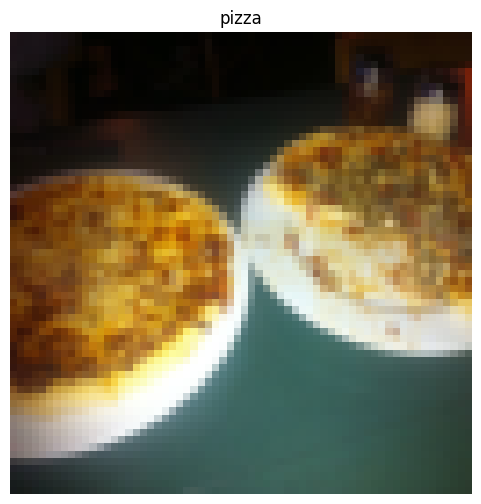

In [18]:
plt.figure(figsize=(6, 6))
plt.imshow(image.permute(1, 2, 0))
plt.title(class_names[label])
plt.axis(False)

In [19]:
import os
print(os.cpu_count())

32


In [ ]:
# turn into dataloader

BATCH_SIZE = 1
train_dataloader = DataLoader(dataset=train_dataset,
                              batch_size=BATCH_SIZE,
                              shuffle=True,
                              num_workers=2 # 使用的子进程数量, 使用子进程可以避免和主进程的计算争抢资源和时间, 默认为0, 一般不超过8
                            )

test_dataloader = DataLoader(dataset=test_dataset,
                              batch_size=BATCH_SIZE,
                              shuffle=False,
                              num_workers=2
                            )

train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x2963b88d640>,
 <torch.utils.data.dataloader.DataLoader at 0x2963b87eab0>)

In [21]:
len(train_dataloader), len(test_dataloader)

(225, 75)

In [22]:
img, label = next(iter(train_dataloader))
img.shape, label.shape

(torch.Size([1, 3, 64, 64]), torch.Size([1]))

## Option2: Load images with a custom dataset

custom dataset: subclass `torch.utils.data.Dataset` and implement `__len__` and `__getitem__`

In [23]:
train_dataset.classes, train_dataset.class_to_idx

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

In [ ]:
import pathlib
from typing import Tuple, Dict, List

list(os.scandir(TRAIN_PATH))

[<DirEntry 'pizza'>, <DirEntry 'steak'>, <DirEntry 'sushi'>]

In [32]:
list(os.scandir(TRAIN_PATH))[0].name, list(os.scandir(TRAIN_PATH))[0].is_dir()

('pizza', True)

In [34]:
def find_classes(directory: str | Path) -> Tuple[List[str], Dict[str, int]]:
    classes = sorted(entry.name for entry in list(os.scandir(TRAIN_PATH)) if entry.is_dir())
    if not classes:
        raise FileNotFoundError(f"Couldn't find any classes in {directory}... please check file structure.")
    class_to_idx = { class_name: i for i, class_name in enumerate(classes)}
    return (classes, class_to_idx)
find_classes(TRAIN_PATH)

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

In [ ]:
from torch.utils.data import Dataset # 其它的Dataset都是这个Dataset的子类

class ImageFolderCustom(Dataset):
    def __init__(self, targ_dir: str | Path, transform=None):
        super().__init__()
        self.paths = list(Path(targ_dir).glob("*/*.jpg"))
        self.transform = transform
        self.classes, self.class_to_idx = find_classes(targ_dir)
        
    def load_image(self, index: int) -> Image.Image:
        path = self.paths[index]
        return Image.open(path)
    
    def __len__(self) -> int:
        return len(self.paths)
    
    def __getitem__(self, index: int) -> Tuple[torch.Tensor, int]:
        img = self.load_image(index)
        class_name = self.paths[index].parent.stem
        label = self.class_to_idx[class_name]
        
        if self.transform is not None:
            return self.transform(img), label
        else:
            return torch.tensor(img), label

In [37]:
transform_train = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

transform_test = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.ToTensor()
])

In [38]:
train_dataset_custom = ImageFolderCustom(TRAIN_PATH, transform_train)
test_dataset_custom = ImageFolderCustom(TEST_PATH, transform_test)

In [39]:
train_dataset_custom, test_dataset_custom

(<__main__.ImageFolderCustom at 0x2963ce26180>,
 <__main__.ImageFolderCustom at 0x2963ce6c7d0>)

In [40]:
len(train_dataset), len(train_dataset_custom)

(225, 225)

In [41]:
train_dataset_custom.classes, train_dataset_custom.class_to_idx

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

In [48]:
# visualize
def plot_random_images(dataset: Dataset, 
                       classes: List[str] | None=None, 
                       display_shape: bool=True, 
                       n: int=10, 
                       seed: int | None=None) -> None:
    if n > 10:
        n = 10
        display_shape = False
        print(f"{n} > 10, 重新设置为10并关闭display_shape, 以保证良好的绘图效果")
    
    if seed is not None:
        random.seed(seed)
    
    ran_samples_idx = random.sample(range(len(dataset)), k=n)

    plt.figure(figsize=(16, 8))
    for i, idx in enumerate(ran_samples_idx):
        img, label = dataset[idx]
        img_adjusted = img.permute(1, 2, 0)
        
        plt.subplot(1, n, i+1)
        plt.imshow(img_adjusted)
        plt.axis(False)
        
        if classes is not None:
            title = classes[label]
            if display_shape:
                title += f"\nShape: {img_adjusted.shape}"
            plt.title(title)

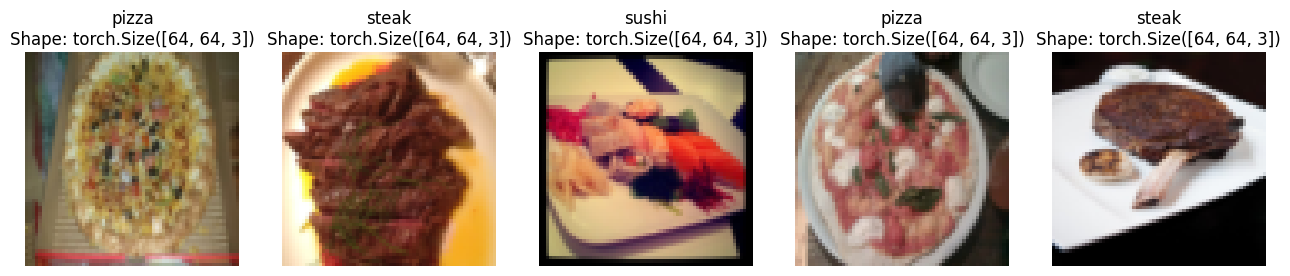

In [49]:
plot_random_images(train_dataset, class_names, True, 5)

10 > 10, 重新设置为10并关闭display_shape, 以保证良好的绘图效果


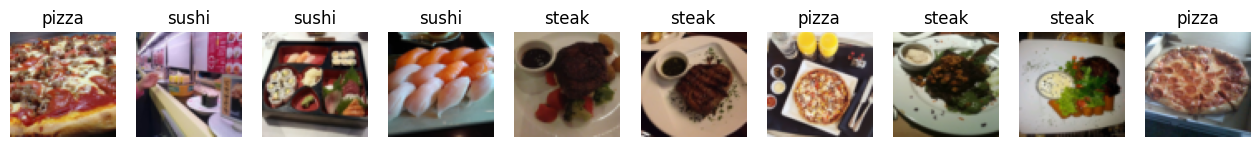

In [50]:
plot_random_images(train_dataset_custom, class_names, True, 12)


In [51]:
# turn into datalaoders
BATCH_SIZE = 32
NUM_WORKERS = 0

train_dataloader_custom = DataLoader(train_dataset_custom, BATCH_SIZE, True, num_workers=NUM_WORKERS)
test_dataloader_custom = DataLoader(test_dataset_custom, BATCH_SIZE, False, num_workers=NUM_WORKERS)

train_dataloader_custom, test_dataloader_custom

(<torch.utils.data.dataloader.DataLoader at 0x2963d936f30>,
 <torch.utils.data.dataloader.DataLoader at 0x2963ce7b1a0>)

In [54]:
img_custom, label_custom = next(iter(train_dataloader_custom))
img_custom.shape, label_custom.shape

(torch.Size([32, 3, 64, 64]), torch.Size([32]))

# 4. Other forms of transformation

data augmentation - 自动给你的数据添加一些随机的变化, 增加数据多样性, 有：AutoAugment, RandAugment, TrivialAugmentWide...

以 Trivial Augmentation 为例

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize(size=(224, 224)),
    transforms.TrivialAugmentWide(5), # bins: intensity的上界, 最高31, 会随机选择[0, bins]
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize(size=(224, 224)),
    transforms.ToTensor()
])
train_transform, test_transform

(Compose(
     Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
     TrivialAugmentWide(num_magnitude_bins=5, interpolation=InterpolationMode.NEAREST, fill=None)
     ToTensor()
 ),
 Compose(
     Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
     ToTensor()
 ))

In [65]:
sample_path_list = list(IMAGE_PATH.glob("train/*/*.jpg"))[:10]
sample_path_list

[WindowsPath('data/pizza_steak_sushi/train/pizza/1008844.jpg'),
 WindowsPath('data/pizza_steak_sushi/train/pizza/1033251.jpg'),
 WindowsPath('data/pizza_steak_sushi/train/pizza/1044789.jpg'),
 WindowsPath('data/pizza_steak_sushi/train/pizza/1089334.jpg'),
 WindowsPath('data/pizza_steak_sushi/train/pizza/1105700.jpg'),
 WindowsPath('data/pizza_steak_sushi/train/pizza/12301.jpg'),
 WindowsPath('data/pizza_steak_sushi/train/pizza/1285298.jpg'),
 WindowsPath('data/pizza_steak_sushi/train/pizza/138855.jpg'),
 WindowsPath('data/pizza_steak_sushi/train/pizza/1412034.jpg'),
 WindowsPath('data/pizza_steak_sushi/train/pizza/1524655.jpg')]

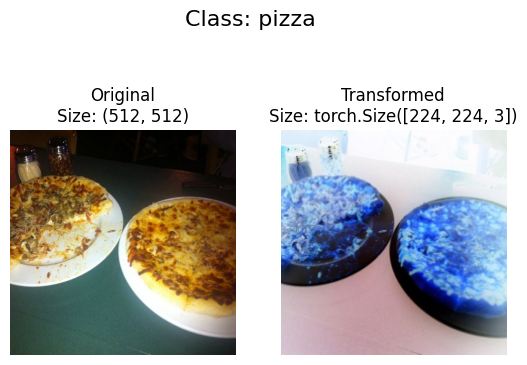

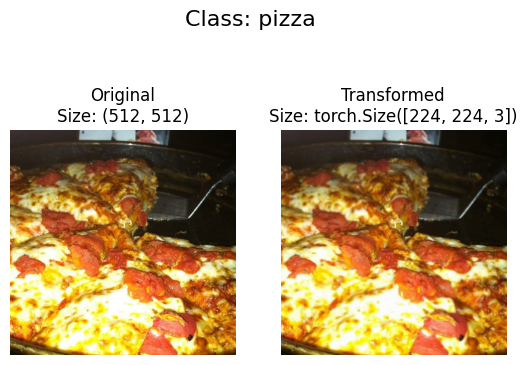

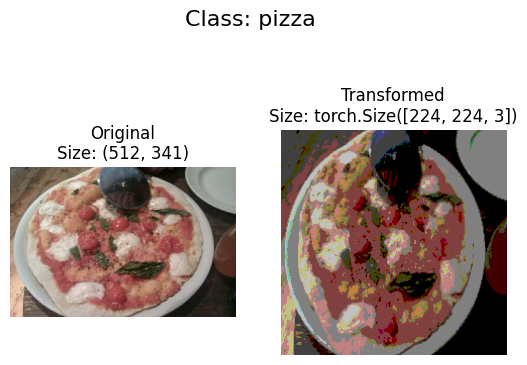

In [66]:
plot_random_transformed_img(sample_path_list, train_transform, 3, None)

# 5. Baseline - TinyVGG without data augmentation

## 5.1 Setup data

In [84]:
# 使用新版transform, 大部分相同
import torchvision.transforms.v2 as T
simple_transform = T.Compose([
    T.Resize(size=(64, 64)),
    # ToTensor() -> ToImage() + ToDtype()
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True) # scale=True: int转化为float后缩放到[0, 1]
])
simple_transform

Compose(
      Resize(size=[64, 64], interpolation=InterpolationMode.BILINEAR, antialias=True)
      ToImage()
      ToDtype(scale=True)
)

In [85]:
train_data_simple = datasets.ImageFolder(TRAIN_PATH, simple_transform, None)
test_data_simple = datasets.ImageFolder(TEST_PATH, simple_transform, None)

train_dataloader_simple = DataLoader(train_data_simple, BATCH_SIZE, True, num_workers=NUM_WORKERS)
test_dataloader_simple = DataLoader(test_data_simple, BATCH_SIZE, False, num_workers=NUM_WORKERS)

## 5.2 Build and Create Model

In [94]:
class TinyVGG(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape, out_channels=hidden_units, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*13*13, out_features=output_shape)
        )
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.conv_block_2(self.conv_block_1(x)))
    

In [95]:
next(iter(train_dataloader_simple))[0].shape

torch.Size([32, 3, 64, 64])

In [96]:
base_model = TinyVGG(3, 10, len(class_names)).to(device)
base_model

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1690, out_features=3, bias=True)
  )
)

## 5.3 使用torchinfo打印model的summary

In [98]:
from torchinfo import summary

summary(base_model, input_size=[1, 3, 64, 64])

Layer (type:depth-idx)                   Output Shape              Param #
TinyVGG                                  [1, 3]                    --
├─Sequential: 1-1                        [1, 10, 30, 30]           --
│    └─Conv2d: 2-1                       [1, 10, 62, 62]           280
│    └─ReLU: 2-2                         [1, 10, 62, 62]           --
│    └─Conv2d: 2-3                       [1, 10, 60, 60]           910
│    └─ReLU: 2-4                         [1, 10, 60, 60]           --
│    └─MaxPool2d: 2-5                    [1, 10, 30, 30]           --
├─Sequential: 1-2                        [1, 10, 13, 13]           --
│    └─Conv2d: 2-6                       [1, 10, 28, 28]           910
│    └─ReLU: 2-7                         [1, 10, 28, 28]           --
│    └─Conv2d: 2-8                       [1, 10, 26, 26]           910
│    └─ReLU: 2-9                         [1, 10, 26, 26]           --
│    └─MaxPool2d: 2-10                   [1, 10, 13, 13]           --
├─Sequentia

## 5.4 创建Training, Testing loop function

In [101]:
len(train_data_simple), len(train_dataloader_simple)*BATCH_SIZE

(225, 256)

In [104]:
label = next(iter(train_dataloader_simple))[1]
label

tensor([0, 0, 1, 0, 2, 2, 0, 1, 2, 1, 1, 2, 0, 2, 2, 0, 0, 2, 1, 1, 1, 0, 1, 1,
        2, 2, 1, 1, 2, 0, 1, 2])

In [116]:
from helper_functions import accuracy_fn

def train_step(model: nn.Module, dataloader: torch.utils.data.DataLoader, loss_fn: nn.Module, optimizer: torch.optim.Optimizer, device: str=device, random_seed: int | None=None):
    if random_seed is not None:
        torch.manual_seed(random_seed)
    model.train()
    train_loss, train_acc = 0, 0
    for X, y in dataloader:
        X, y = X.to(device), y.to(device)
        y_logits = model(X)
        loss = loss_fn(y_logits, y)
        train_loss += loss.item()
        train_acc += accuracy_fn(y, y_logits.argmax(dim=1))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    train_loss /= len(dataloader)
    train_acc /= len(dataloader)
    return train_loss, train_acc

def test_step(model: nn.Module, dataloader: torch.utils.data.DataLoader, loss_fn: nn.Module, device: str=device, random_seed: int | None=None):
    model.eval()
    with torch.inference_mode():
        test_loss, test_acc = 0, 0
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            y_logits = model(X)
            test_loss += loss_fn(y_logits, y).item()
            test_acc += accuracy_fn(y, y_logits.argmax(dim=1))
        test_loss /= len(dataloader)
        test_acc /= len(dataloader)
    return test_loss, test_acc

In [117]:
from tqdm.auto import tqdm, trange

def train(model: nn.Module, 
          train_dataloader: torch.utils.data.DataLoader, 
          test_dataloader: torch.utils.data.DataLoader, 
          optimizer: torch.optim.Optimizer, 
          loss_fn: nn.Module=nn.CrossEntropyLoss(), 
          device: str=device, 
          random_seed: int | None=None, 
          epochs: int=5):
    results = {
        "train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": []
    }
    for epoch in trange(epochs):
        print(f"Epoch {epoch + 1}")
        train_loss, train_acc = train_step(model, train_dataloader, loss_fn, optimizer, device, random_seed)
        test_loss, test_acc = test_step(model, test_dataloader, loss_fn, device, random_seed)
        print(f"Train loss: {train_loss:.5f} | Train acc: {train_acc:.2f}% | Test loss: {test_loss:.5f} | Test acc: {test_acc:.2f}%")
        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)
    
    return results

## 5.5 Train and Evaluate Baseline Model

In [125]:
from timeit import default_timer as timer

base_model = TinyVGG(3, 10, len(class_names)).to(device)
optimizer = torch.optim.Adam(params= base_model.parameters(), lr=0.001)
    
torch.manual_seed(RANDOM_SEED)

base_start_time = timer()
baseline_results = train(model= base_model,
                         train_dataloader= train_dataloader_simple,
                         test_dataloader= test_dataloader_simple,
                         optimizer= optimizer,
                         device=device,
                         epochs=30,
                         random_seed=RANDOM_SEED)
base_end_time = timer()
base_total_time = base_end_time - base_start_time
print(f"\nTraining time: {base_total_time:.3f} seconds")

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 1
Train loss: 1.10343 | Train acc: 28.12% | Test loss: 1.09943 | Test acc: 26.04%
Epoch 2
Train loss: 1.08047 | Train acc: 42.58% | Test loss: 1.12544 | Test acc: 26.04%
Epoch 3
Train loss: 1.07229 | Train acc: 42.58% | Test loss: 1.14878 | Test acc: 26.04%
Epoch 4
Train loss: 1.07146 | Train acc: 42.58% | Test loss: 1.15935 | Test acc: 26.04%
Epoch 5
Train loss: 1.06848 | Train acc: 42.58% | Test loss: 1.15622 | Test acc: 26.04%
Epoch 6
Train loss: 1.05646 | Train acc: 42.58% | Test loss: 1.14326 | Test acc: 26.04%
Epoch 7
Train loss: 1.03097 | Train acc: 43.36% | Test loss: 1.11755 | Test acc: 27.08%
Epoch 8
Train loss: 0.98319 | Train acc: 52.34% | Test loss: 1.07267 | Test acc: 35.32%
Epoch 9
Train loss: 0.89525 | Train acc: 57.81% | Test loss: 1.03702 | Test acc: 33.24%
Epoch 10
Train loss: 0.80831 | Train acc: 60.16% | Test loss: 1.03016 | Test acc: 38.35%
Epoch 11
Train loss: 0.77469 | Train acc: 63.67% | Test loss: 1.01834 | Test acc: 35.23%
Epoch 12
Train loss: 0.75156 |

## 5.6 Plot loss curve

In [126]:
baseline_results

{'train_loss': [1.1034318506717682,
  1.0804731249809265,
  1.0722888112068176,
  1.0714572966098785,
  1.0684775188565254,
  1.056464433670044,
  1.030967615544796,
  0.983190692961216,
  0.895247645676136,
  0.8083121180534363,
  0.7746942900121212,
  0.7515649441629648,
  0.7242388445883989,
  0.6992967501282692,
  0.6803299011662602,
  0.6742384387180209,
  0.6450895899906754,
  0.613791516982019,
  0.600483728107065,
  0.5983333187177777,
  0.5908168563619256,
  0.5653750030323863,
  0.5419417433440685,
  0.5237982287071645,
  0.5108947844710201,
  0.5022208706941456,
  0.49925759620964527,
  0.5002593318931758,
  0.4831911758519709,
  0.45230245124548674],
 'train_acc': [28.125,
  42.578125,
  42.578125,
  42.578125,
  42.578125,
  42.578125,
  43.359375,
  52.34375,
  57.8125,
  60.15625,
  63.671875,
  65.625,
  67.1875,
  68.359375,
  69.140625,
  70.3125,
  70.703125,
  72.265625,
  72.65625,
  72.65625,
  74.609375,
  75.390625,
  76.5625,
  79.296875,
  80.46875,
  82.03125

In [127]:
def plot_loss_curves(results: Dict[str, List[float]]) -> None:
    train_loss = results["train_loss"]
    test_loss = results["test_loss"]
    train_acc = results["train_acc"]
    test_acc = results["test_acc"]
    epochs = range(len(train_loss))
    
    plt.figure(figsize=(17, 8))
    
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_loss, label="training loss")
    plt.plot(epochs, test_loss, label="testing loss")
    plt.title("loss")
    plt.xlabel("Epochs")
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_acc, label="training accuracy")
    plt.plot(epochs, test_acc, label="testing accuracy")
    plt.title("accuracy")
    plt.xlabel("Epochs")
    plt.legend()

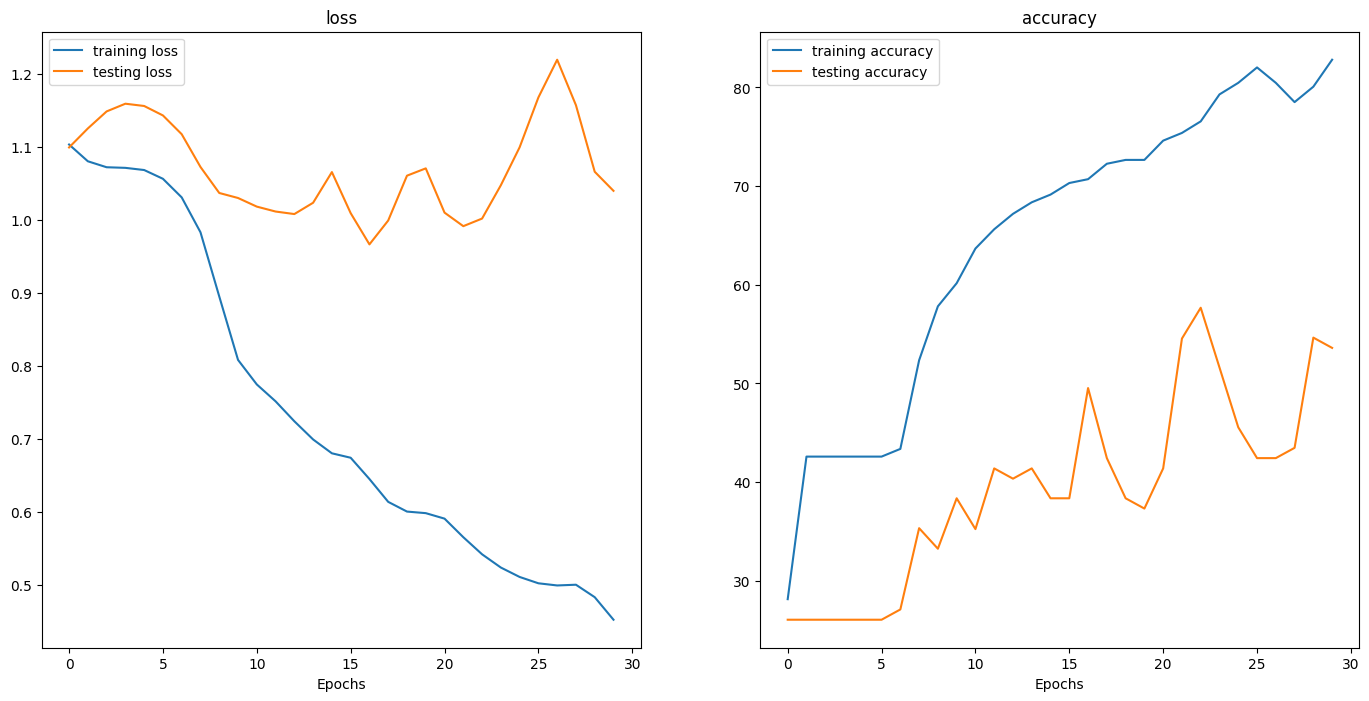

In [128]:
plot_loss_curves(baseline_results)

从上图看到 training 和 testing 的loss curve差距越来越大, 说明 overfitting了

而实际情况也确实是这样。在训练集上表现远远好于测试集上的表现

# 6. Data Augmentation to prevent overfitting

In [131]:
transform_augmentation = T.Compose([
    T.Resize(size=(64, 64)),
    T.TrivialAugmentWide(31),
    T.ToImage(),
    T.ToDtype(torch.float32, True)
])

train_data_augmentaion = datasets.ImageFolder(TRAIN_PATH, transform_augmentation)
train_dataloader_augmentation = DataLoader(train_data_augmentaion, BATCH_SIZE, True, num_workers=NUM_WORKERS)

test_data_simple = datasets.ImageFolder(TEST_PATH, simple_transform, None)
test_dataloader_simple = DataLoader(test_data_simple, BATCH_SIZE, False, num_workers=NUM_WORKERS)

In [136]:
model_1 = TinyVGG(3, 10, len(class_names)).to(device)
optimizer = torch.optim.Adam(params= model_1.parameters(), lr=0.001)
    
torch.manual_seed(RANDOM_SEED)

base_start_time = timer()
model_1_results = train(model= model_1,
                         train_dataloader= train_dataloader_augmentation,
                         test_dataloader= test_dataloader_simple,
                         optimizer= optimizer,
                         device=device,
                         epochs=30,
                         random_seed=RANDOM_SEED)
base_end_time = timer()
base_total_time = base_end_time - base_start_time
print(f"\nTraining time: {base_total_time:.3f} seconds")

  0%|          | 0/30 [00:00<?, ?it/s]

Epoch 1
Train loss: 1.10396 | Train acc: 25.00% | Test loss: 1.09374 | Test acc: 54.17%
Epoch 2
Train loss: 1.08898 | Train acc: 45.70% | Test loss: 1.10595 | Test acc: 26.04%
Epoch 3
Train loss: 1.07242 | Train acc: 42.58% | Test loss: 1.13227 | Test acc: 26.04%
Epoch 4
Train loss: 1.06149 | Train acc: 42.58% | Test loss: 1.14696 | Test acc: 26.04%
Epoch 5
Train loss: 1.04801 | Train acc: 42.58% | Test loss: 1.13058 | Test acc: 26.04%
Epoch 6
Train loss: 1.02126 | Train acc: 42.58% | Test loss: 1.10639 | Test acc: 26.04%
Epoch 7
Train loss: 0.97313 | Train acc: 46.88% | Test loss: 1.08508 | Test acc: 32.20%
Epoch 8
Train loss: 0.90842 | Train acc: 55.86% | Test loss: 1.07279 | Test acc: 40.44%
Epoch 9
Train loss: 0.85747 | Train acc: 57.42% | Test loss: 1.11770 | Test acc: 40.44%
Epoch 10
Train loss: 0.84813 | Train acc: 58.20% | Test loss: 1.07138 | Test acc: 40.44%
Epoch 11
Train loss: 0.80971 | Train acc: 60.55% | Test loss: 1.07130 | Test acc: 37.41%
Epoch 12
Train loss: 0.78307 |

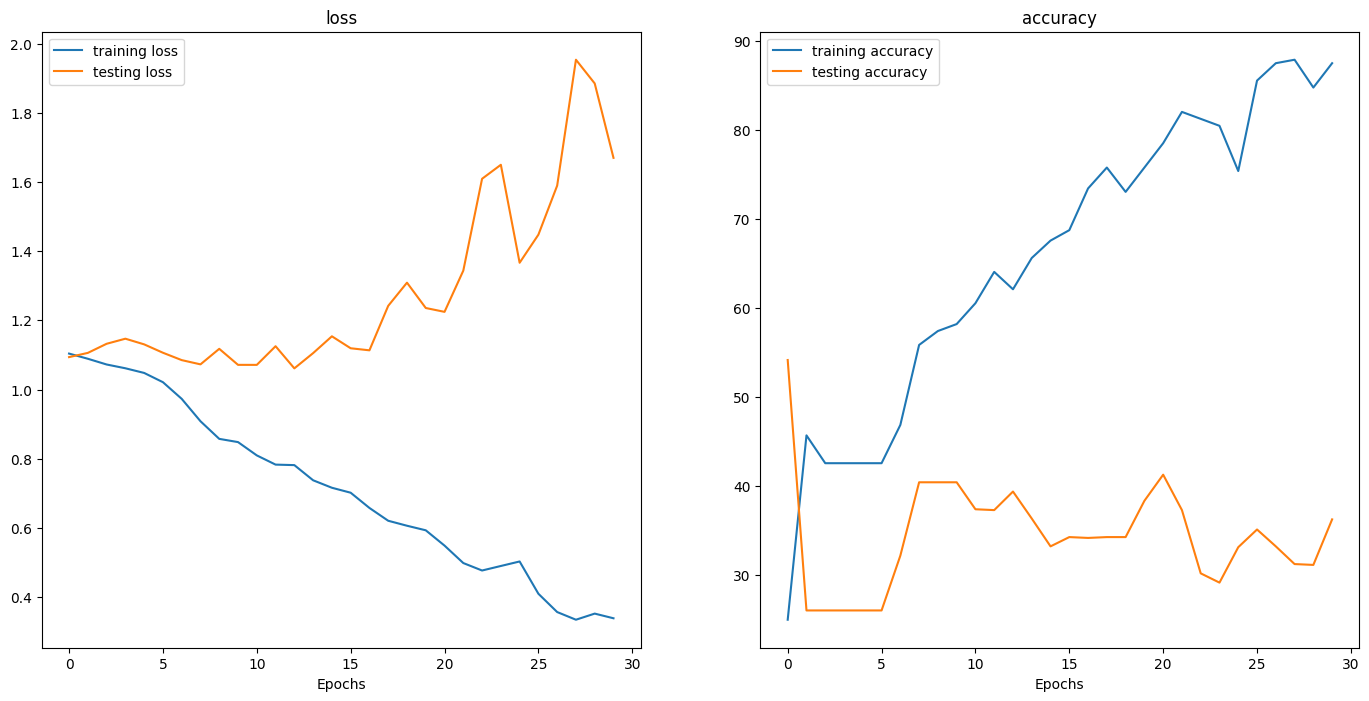

In [137]:
plot_loss_curves(model_1_results)

# 7. Compare model results

1. Hard coding
2. PyTorch + TensorBoard
3. weights & bias https://wandb.ai/site
4. MLFlow

# 8. Predict on testing data(不在training和testing data中的data)

In [143]:
# download custom image
custom_img_path = DATA_DIR / "04-test_pizza.png"

if not custom_img_path.is_file():
    with open(custom_img_path, "wb") as f:
        request = requests.get("https://tse3.mm.bing.net/th/id/OIP.5ss0Np4_jqHlZAkJsGsrTQHaFj?rs=1&pid=ImgDetMain&o=7&rm=3")
        print(f"downloading to {custom_img_path}")
        f.write(request.content)
else:
    print("image already exists.")
        

downloading to data\04-test_pizza.png


In [144]:
import torchvision
# load image and transform it
# 必须和训练时的格式一样(tensor, 大小, device)

custom_image_uint8 = torchvision.io.read_image(str(custom_img_path))
print(f"Tensor:\n{custom_image_uint8}\n")
print(f"Tensor shape: {custom_image_uint8.shape}")
print(f"Tensor dtype: {custom_image_uint8.dtype}")

Tensor:
tensor([[[ 42,  42,  42,  ..., 121, 125, 125],
         [ 41,  41,  41,  ..., 119, 122, 122],
         [ 39,  39,  39,  ..., 118, 118, 118],
         ...,
         [ 42,  23,  40,  ...,  66,  70,  83],
         [ 59,  26,  26,  ...,  51,  62,  82],
         [ 62,  22,  23,  ...,  54,  54,  82]],

        [[ 15,  15,  15,  ..., 108, 114, 114],
         [ 16,  16,  16,  ..., 107, 110, 110],
         [ 17,  17,  17,  ..., 106, 107, 107],
         ...,
         [ 24,   6,  20,  ...,  32,  36,  49],
         [ 48,  12,  10,  ...,  19,  30,  50],
         [ 50,   8,   7,  ...,  24,  24,  52]],

        [[ 15,  15,  15,  ...,  85,  88,  88],
         [ 15,  15,  15,  ...,  84,  84,  84],
         [ 15,  15,  15,  ...,  83,  81,  81],
         ...,
         [ 21,   2,  16,  ...,  17,  20,  33],
         [ 49,  14,  11,  ...,   7,  18,  38],
         [ 52,  11,   8,  ...,  11,  11,  39]]], dtype=torch.uint8)

Tensor shape: torch.Size([3, 355, 474])
Tensor dtype: torch.uint8


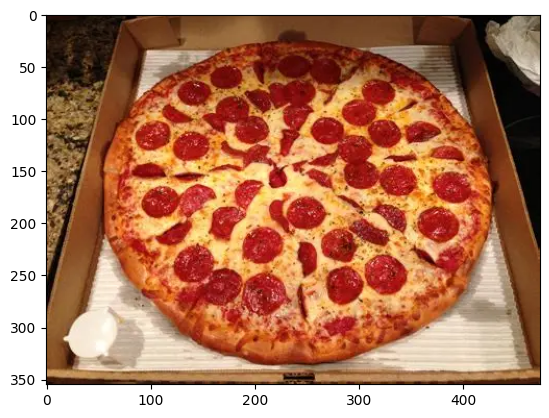

In [146]:
plt.imshow(custom_image_uint8.permute(1, 2, 0))

In [148]:
custom_image_transformed = simple_transform(custom_image_uint8)
print(f"Tensor:\n{custom_image_transformed}\n")
print(f"Tensor shape: {custom_image_transformed.shape}")
print(f"Tensor dtype: {custom_image_transformed.dtype}")

Tensor:
Image([[[0.1333, 0.1412, 0.1373,  ..., 0.5725, 0.4588, 0.4706],
        [0.0863, 0.0902, 0.1020,  ..., 0.5882, 0.5020, 0.4431],
        [0.1137, 0.1020, 0.1333,  ..., 0.5843, 0.5020, 0.4039],
        ...,
        [0.6431, 0.6314, 0.5765,  ..., 0.6510, 0.6157, 0.5333],
        [0.6039, 0.6314, 0.6627,  ..., 0.6549, 0.6549, 0.6196],
        [0.2235, 0.2745, 0.2980,  ..., 0.3725, 0.3490, 0.3098]],

       [[0.0588, 0.0549, 0.0549,  ..., 0.5255, 0.4157, 0.4275],
        [0.0471, 0.0471, 0.0549,  ..., 0.5412, 0.4549, 0.3961],
        [0.0745, 0.0588, 0.0824,  ..., 0.5333, 0.4431, 0.3451],
        ...,
        [0.4353, 0.4275, 0.3882,  ..., 0.5059, 0.4471, 0.3490],
        [0.4275, 0.4549, 0.4863,  ..., 0.4627, 0.4471, 0.4118],
        [0.1059, 0.1412, 0.1529,  ..., 0.2000, 0.1804, 0.1569]],

       [[0.0431, 0.0353, 0.0392,  ..., 0.4431, 0.3333, 0.3373],
        [0.0196, 0.0157, 0.0235,  ..., 0.4588, 0.3725, 0.3098],
        [0.0392, 0.0275, 0.0431,  ..., 0.4431, 0.3529, 0.2549],
  

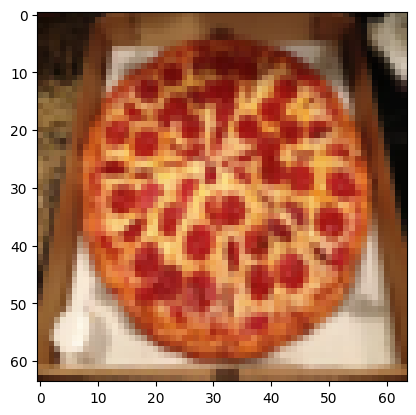

In [149]:
plt.imshow(custom_image_transformed.permute(1, 2, 0))

In [160]:
model_1.eval()
with torch.inference_mode():
    res = model_1(custom_image_transformed.unsqueeze(dim=0).to(device))
torch.softmax(res, dim=1), class_names[torch.softmax(res, dim=1).argmax(dim=1)]

(tensor([[8.3365e-01, 4.7474e-04, 1.6588e-01]], device='cuda:0'), 'pizza')

In [157]:
# functionize it
def predict_image_type(model: nn.Module, path: str | Path, device: str=device) -> str:
    img = torchvision.io.read_image(str(path))
    transformed_img = simple_transform(img)
    
    model.eval()
    with torch.inference_mode():
        res = model(transformed_img.unsqueeze(dim=0).to(device))
    return class_names[torch.softmax(res, dim=1).argmax(dim=1)]

In [158]:
predict_image_type(model_1, custom_img_path, device)

'pizza'